# Peak Fitting

In this Notebook, the peak fitting process of `fcs_data` is demonstrated.
First, a mass spectrum is loaded and plotted.
Then, a non-overlapping C<sub>60</sub>Nb<sub>n</sub><sup>+</sup> peak is fitted.
Finally, two mass-overlapping C<sub>60</sub>Nb<sub>n</sub>[D<sub>2</sub>]<sup>+</sup> peaks are fitted using the results from the clean reference fit.

# Imports

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
from lmfit import Model

from fcs_data import MassSpec

# Loading a mass spectrum

This section shows the very basic elements of `fcs_data`:

- Data loading
- Mass calibration
- Plotting

In [2]:
# init_params = (G, t_off), the initial calibration parameters
G = 0.09267516
t_off = 0.36855249

ms = MassSpec(Path("data/MassSpectrum_C60Nb.npy"), init_params=(G, t_off))

_ = ms.time      # time axis (µs)
_ = ms.mass      # mass axis, from the calibration
_ = ms.voltage   # baseline-corrected signal (accumulated voltage)
_ = ms.baseline  # the baseline that was subtracted

ms.calibrate(G, t_off) # To change the initial calibration parameters and redo calibration


## Plotting

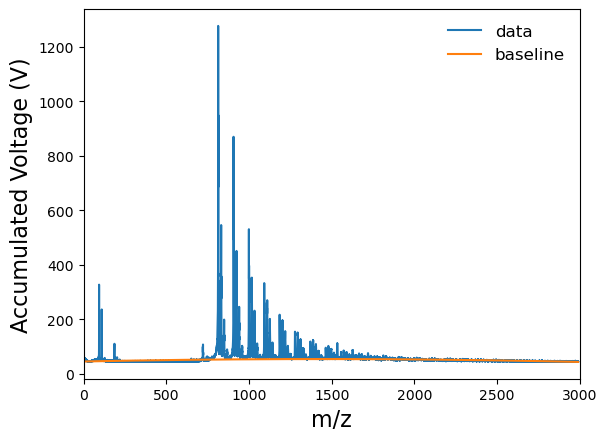

In [3]:
fig, ax = plt.subplots()

plt.plot(ms.mass, ms.voltage + ms.baseline, label='data')
plt.plot(ms.mass, ms.baseline, label='baseline')

plt.legend(frameon=False, fontsize=12)

plt.ylabel("Accumulated Voltage (V)", fontsize=16)
plt.xlabel("m/z", fontsize=16)

plt.xlim([0, 3000])

plt.show()

# Peak Fitting

## Choose mass range

First, the peak(s) of interest are plotted to get an idea of what mass range should be considered.

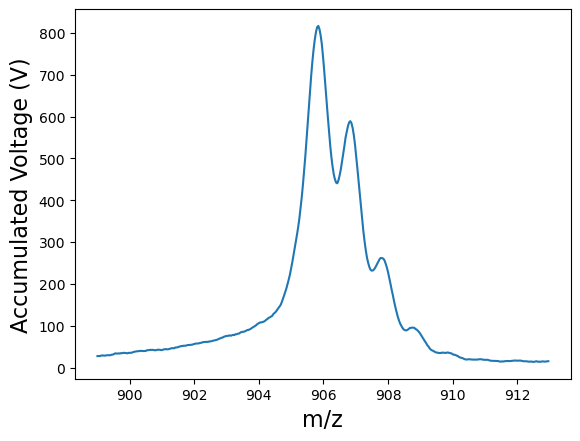

In [4]:
MASS = 906  # C60Nb2
PAD = 7

# Apply mass filter to select range
x, y = ms.mass_filter([MASS - PAD, MASS + PAD])

# Plot
fig, ax = plt.subplots()

plt.plot(x, y, label='data')


plt.ylabel("Accumulated Voltage (V)", fontsize=16)
plt.xlabel("m/z", fontsize=16)

plt.show()

## Fit: Reference

Fit a simple lmfit `Model` build from the `c60` lineshape that is defined in `fcs_data.lineshapes`.

It follows the steps from lmfit (see [documentation](https://lmfit.github.io/lmfit-py/) for details).
In summary, a model is created and a parameter object is generated. Then, the initial values are provided.

[[Model]]
    Model(c60)
[[Fit Statistics]]
    # fitting method   = leastsq
    # function evals   = 65
    # data points      = 382
    # variables        = 8
    chi-square         = 48782.8628
    reduced chi-square = 130.435462
    Akaike info crit   = 1868.59065
    Bayesian info crit = 1900.15402
    R-squared          = 0.99646455
[[Variables]]
    h0:      693.094562 +/- 4.16182777 (0.60%) (init = 800)
    h1:      527.865106 +/- 3.62159316 (0.69%) (init = 272.2561)
    h2:      242.576766 +/- 3.18047037 (1.31%) (init = 86.8671)
    h3:      97.7349631 +/- 2.89525385 (2.96%) (init = 6.503312)
    center:  905.813966 +/- 0.00236423 (0.00%) (init = 906)
    width:   0.74477169 +/- 0.00504502 (0.68%) (init = 2)
    a:       0.49895825 +/- 0.00422860 (0.85%) (init = 0.5)
    b:       0.42490607 +/- 0.01200548 (2.83%) (init = 0.5)
[[Correlations]] (unreported correlations are < 0.100)
    C(a, b)          = -0.8519
    C(width, b)      = -0.6440
    C(width, a)      = +0.4557
    C

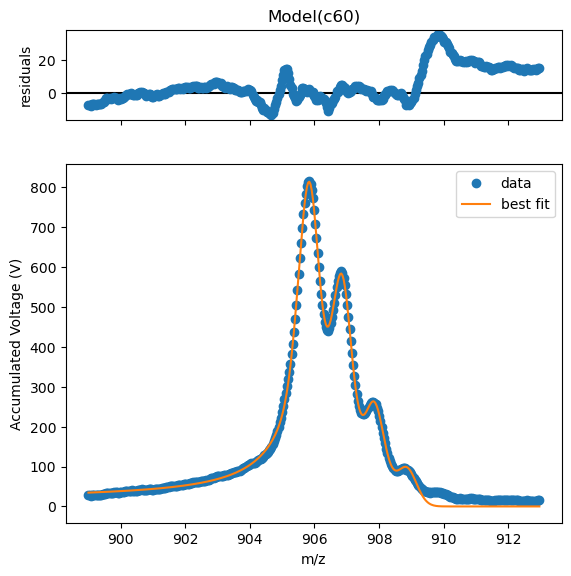

In [5]:
from scipy.stats import binom

from fcs_data.lineshapes import c60

PC13 = 0.0107   # Abundance of carbon-13


# Initial paramters
amplitude = 800
center = MASS
mass_range = (MASS - PAD, MASS + PAD)

# Define lmfit model
model = Model(c60)
params = model.make_params(
    h0 = amplitude,
    h1 = amplitude * binom.pmf(1, 60, PC13),    
    h2 = amplitude * binom.pmf(2, 60, PC13),
    h3 = amplitude * binom.pmf(3, 40, PC13),
    center = center,
    width = 2,
    a = 0.5,
    b = 0.5
)

# Run the fit
result = ms.fit(model, mass_range, params)
result.plot(
    xlabel="m/z",
    ylabel="Accumulated Voltage (V)")
print(result.fit_report())

## Fit: Overlap

Finally, two mass-overlapping peaks are fitted.
First, a plot is made the get an idea of the mass range.

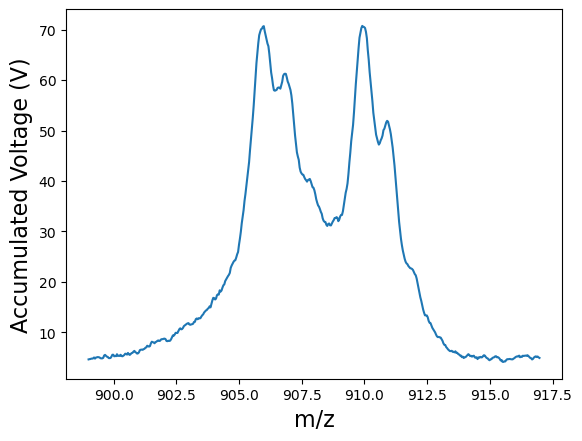

In [6]:
ADDED_MASS = 4 # Mass D2


ms_overlap = MassSpec(
    Path("data/MassSpectrum_C60Nb_D2.npy"), 
    init_params=(G, t_off))
mass_range = (MASS - PAD, MASS + ADDED_MASS + PAD)

x, y = ms_overlap.mass_filter(mass_range)

# Plot
fig, ax = plt.subplots()

plt.plot(x, y, label='data')


plt.ylabel("Accumulated Voltage (V)", fontsize=16)
plt.xlabel("m/z", fontsize=16)

plt.show()

### Define lmfit model

Defines a composite model consisting of two C<sub>60</sub> lineshapes. The parameters of each lineshape are tied to the reference fit so that the peak shapes remain identical, except for a possible resolution loss after collisions in the cell.

The fitting parameters are:

- `center`: position of the main peak, which may shift due to calibration offset after collisions
- `c1`, `c2`: relative contributions of the main and adsorbed peaks; scales the reference image.
- `f`: change in peak width due to resolution loss

[[Model]]
    (Model(c60, prefix='main_') + Model(c60, prefix='ads_'))
[[Fit Statistics]]
    # fitting method   = leastsq
    # function evals   = 46
    # data points      = 491
    # variables        = 4
    chi-square         = 4085.90425
    reduced chi-square = 8.38994713
    Akaike info crit   = 1048.35742
    Bayesian info crit = 1065.14320
    R-squared          = 0.98068622
[[Variables]]
    main_h0:      53.8567309 +/- 0.70685865 (1.31%) == 'c1 * 693.0945618305516'
    main_h1:      41.0176194 +/- 0.53834792 (1.31%) == 'c1 * 527.8651062793082'
    main_h2:      18.8493639 +/- 0.24739407 (1.31%) == 'c1 * 242.57676644204182'
    main_h3:      7.59446964 +/- 0.09967587 (1.31%) == 'c1 * 97.73496310225349'
    main_center:  905.912885 +/- 0.00680772 (0.00%) == 'center'
    main_width:   1.01009864 +/- 0.01428583 (1.41%) == '0.7447716867354406 + f'
    main_a:       0.4989583 (fixed)
    main_b:       0.4249061 (fixed)
    ads_h0:       53.3976219 +/- 0.67489186 (1.26%) == 'c2 * 6

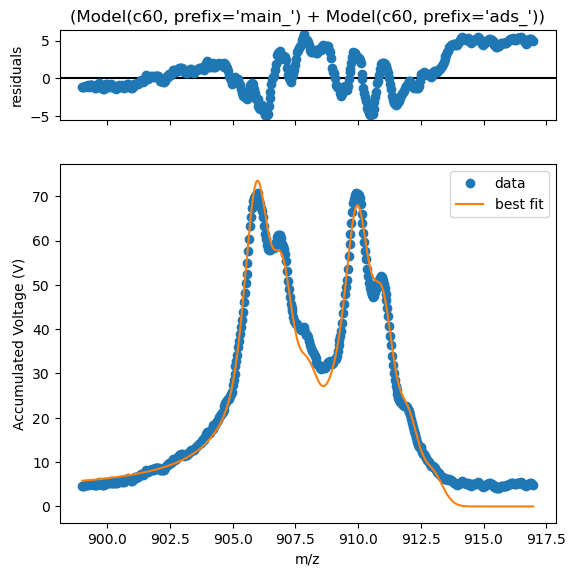

In [7]:
# Take the single peakshape as reference
reference = result.best_values

# Initialise composite model
model_overlap = Model(c60, prefix='main_') + Model(c60, prefix='ads_')
params = model_overlap.make_params()

# Define composite fitting parameters
params.add("center", value=center)  # center of main
params.add("c1", value=0.1, min=0)  # contribution of main
params.add("c2", value=0.1, min=0)  # contribution of ads
params.add("f", value=0)    # resoltution loss

# Tie parameters together
params["main_center"].set(expr="center")
params["ads_center"].set(expr=f"center + {ADDED_MASS}")
for prefix, c in [("main_", "c1"), ("ads_", "c2")]:
    params[prefix + "width"].set(expr=f"{reference['width']} + f")
    for i in range(4): # four isotopes
        params[prefix + f"h{i}"].set(expr=f"{c} * {reference[f'h{i}']}")

# Fix shape parameters
for prefix in ["main_", "ads_"]:
    for key in ("a", "b"):
        params[prefix + key].set(value=reference[key], vary=False)

# Run fit
result = ms_overlap.fit(model_overlap, mass_range, params)
result.plot(
    xlabel="m/z",
    ylabel="Accumulated Voltage (V)")
print(result.fit_report())